In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# =============================================================================
# SECTION 0 : INSTALL REQUIRED LIBRARIES
# =============================================================================

!pip install -q lightgbm
!pip install -q shap
!pip install -q lime
!pip install -q imbalanced-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 8.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
# =============================================================================
# SECTION 1 : IMPORT LIBRARIES
# =============================================================================

# Standard Libraries
import os
import warnings
import joblib

# Numerical Computing
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore Warnings
warnings.filterwarnings("ignore")

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    VotingClassifier,
    StackingClassifier
)

from lightgbm import LGBMClassifier

# Performance Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

# SMOTE
from imblearn.over_sampling import SMOTE

# Explainable AI
import shap
from lime.lime_tabular import LimeTabularExplainer

In [ ]:
# =============================================================================
# SECTION 1 : PROJECT DIRECTORY SETUP
# =============================================================================

PROJECT_DIR = "/content/drive/MyDrive/CKD Research Project"

DATASET_DIR = os.path.join(PROJECT_DIR, "Dataset")

FIGURE_DIR = os.path.join(
    PROJECT_DIR,
    "Figures",
    "Notebook_05_XAI"
)

RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "Results",
    "Notebook_05_XAI"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "Saved_Models"
)

# Create Directories
os.makedirs(FIGURE_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

print("=" * 80)
print("Project directories are ready.")
print("=" * 80)

Project directories are ready.


In [ ]:
# =============================================================================
# SECTION 3 : LOAD DATASET & PREPARE FEATURES
# =============================================================================

# =============================================================================
# SECTION 2 : LOAD DATASET
# =============================================================================

DATA_PATH = os.path.join(DATASET_DIR, "clean_ckd.csv")

df = pd.read_csv(DATA_PATH)

print("=" * 80)
print("Dataset Loaded Successfully")
print("=" * 80)

print(f"Dataset Shape : {df.shape}")

display(df.head())

Dataset Loaded Successfully
Dataset Shape : (399, 25)


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.20000,1,1,0,0,0,0,0
1,7.0,50.0,1.020,4.0,0.0,1,1,0,0,121.0,...,38.0,6000.0,4.70709,0,0,0,0,0,0,0
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,4.70709,0,1,0,1,0,1,0
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,32.0,6700.0,3.90000,1,0,0,1,1,1,0
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,35.0,7300.0,4.60000,0,0,0,0,0,0,0


In [ ]:
# =============================================================================
# SECTION 3 : PREPARE FEATURES & TARGET
# =============================================================================

X = df.drop("class", axis=1)
y = df["class"]

print("=" * 80)
print("Feature Matrix and Target Variable Prepared")
print("=" * 80)

print("Feature Shape :", X.shape)
print("Target Shape  :", y.shape)

Feature Matrix and Target Variable Prepared
Feature Shape : (399, 24)
Target Shape  : (399,)


In [ ]:
# =============================================================================
# SECTION 4 : TRAIN TEST SPLIT
# =============================================================================

RANDOM_STATE = 42
TEST_SIZE = 0.20

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

print("=" * 80)
print("Train-Test Split Completed")
print("=" * 80)

print("Training Samples :", X_train.shape)
print("Testing Samples  :", X_test.shape)

Train-Test Split Completed
Training Samples : (319, 24)
Testing Samples  : (80, 24)


In [ ]:
# =============================================================================
# SECTION 5 : LOAD SAVED EXTRA TREES MODEL
# =============================================================================

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "extra_trees.pkl"
)

extra_tree_model = joblib.load(MODEL_PATH)

print("=" * 80)
print("Extra Trees Model Loaded Successfully")
print("=" * 80)

print(extra_tree_model)

Extra Trees Model Loaded Successfully
ExtraTreesClassifier(random_state=42)


In [ ]:
# =============================================================================
# SECTION 6 : SHAP EXPLAINER INITIALIZATION
# =============================================================================

print("=" * 80)
print("Initializing SHAP Explainer...")
print("=" * 80)

explainer = shap.TreeExplainer(extra_tree_model)

shap_values = explainer.shap_values(X)

print("SHAP values generated successfully.")

print(f"Feature Matrix Shape : {X.shape}")

Initializing SHAP Explainer...
SHAP values generated successfully.
Feature Matrix Shape : (399, 24)


Generating SHAP Summary Plot...


<Figure size 1000x700 with 0 Axes>

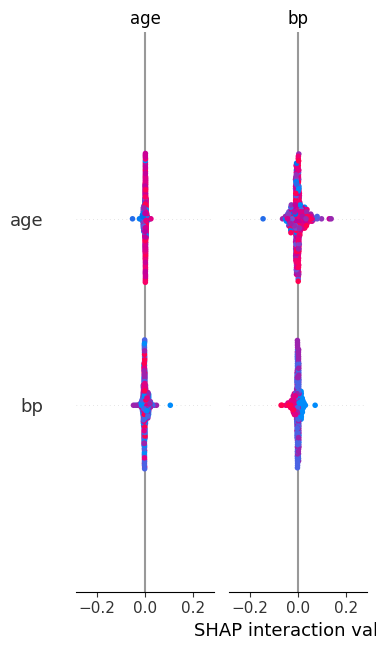

Figure saved to:
/content/drive/MyDrive/CKD Research Project/Figures/Notebook_05_XAI/Figure_01_SHAP_Summary.png


In [ ]:
# =============================================================================
# SECTION 7 : SHAP SUMMARY PLOT
# =============================================================================

print("=" * 80)
print("Generating SHAP Summary Plot...")
print("=" * 80)

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X,
    show=False
)

plt.tight_layout()

summary_path = os.path.join(
    FIGURE_DIR,
    "Figure_01_SHAP_Summary.png"
)

plt.savefig(summary_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to:\n{summary_path}")

Generating SHAP Feature Importance Plot...


<Figure size 1000x700 with 0 Axes>

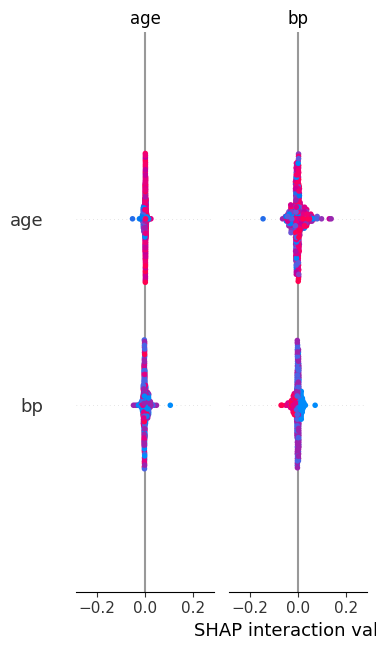

Figure saved to:
/content/drive/MyDrive/CKD Research Project/Figures/Notebook_05_XAI/Figure_02_SHAP_Feature_Importance.png


In [ ]:
# =============================================================================
# SECTION 8 : SHAP FEATURE IMPORTANCE
# =============================================================================

print("=" * 80)
print("Generating SHAP Feature Importance Plot...")
print("=" * 80)

plt.figure(figsize=(10,7))

shap.summary_plot(
    shap_values,
    X,
    plot_type="bar",
    show=False
)

plt.tight_layout()

bar_path = os.path.join(
    FIGURE_DIR,
    "Figure_02_SHAP_Feature_Importance.png"
)

plt.savefig(bar_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to:\n{bar_path}")

In [ ]:
print(type(shap_values))
print(np.array(shap_values).shape)

<class 'numpy.ndarray'>
(399, 24, 2)


Generating SHAP Waterfall Plot...


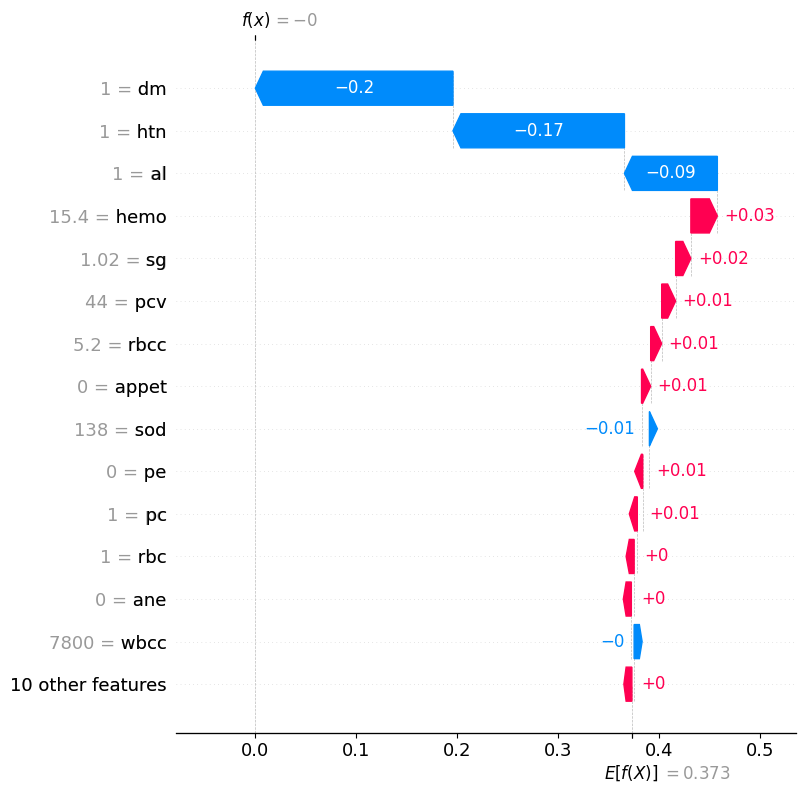

Waterfall plot saved successfully.


In [ ]:
# =============================================================================
# SECTION 9 : SHAP WATERFALL PLOT
# =============================================================================

print("=" * 80)
print("Generating SHAP Waterfall Plot...")
print("=" * 80)

sample_index = 0
class_index = 1      # CKD Class

explanation = shap.Explanation(
    values=shap_values[sample_index, :, class_index],
    base_values=explainer.expected_value[class_index],
    data=X.iloc[sample_index],
    feature_names=X.columns.tolist()
)

plt.figure(figsize=(10,8))

shap.plots.waterfall(
    explanation,
    max_display=15,
    show=False
)

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Figure_03_SHAP_Waterfall.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Waterfall plot saved successfully.")

In [ ]:
# =============================================================================
# SECTION 10 : SHAP FEATURE IMPORTANCE TABLE
# =============================================================================

print("=" * 80)
print("Generating SHAP Feature Importance Table...")
print("=" * 80)

# Mean absolute SHAP values (CKD class = 1)
mean_shap = np.abs(shap_values[:, :, 1]).mean(axis=0)

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Mean_SHAP_Value": mean_shap
})

feature_importance = feature_importance.sort_values(
    by="Mean_SHAP_Value",
    ascending=False
).reset_index(drop=True)

print(feature_importance.head(10))

# Save CSV
csv_path = os.path.join(
    RESULT_DIR,
    "Top10_SHAP_Feature_Importance.csv"
)

feature_importance.head(10).to_csv(
    csv_path,
    index=False
)

print(f"\nResults saved to:\n{csv_path}")

Generating SHAP Feature Importance Table...
  Feature  Mean_SHAP_Value
0      sg         0.080732
1      dm         0.072942
2     htn         0.070147
3      al         0.051970
4     pcv         0.049214
5    hemo         0.048914
6   appet         0.026042
7    rbcc         0.023324
8      pe         0.021133
9      pc         0.017297

Results saved to:
/content/drive/MyDrive/CKD Research Project/Results/Notebook_05_XAI/Top10_SHAP_Feature_Importance.csv


Generating SHAP Dependence Plot...


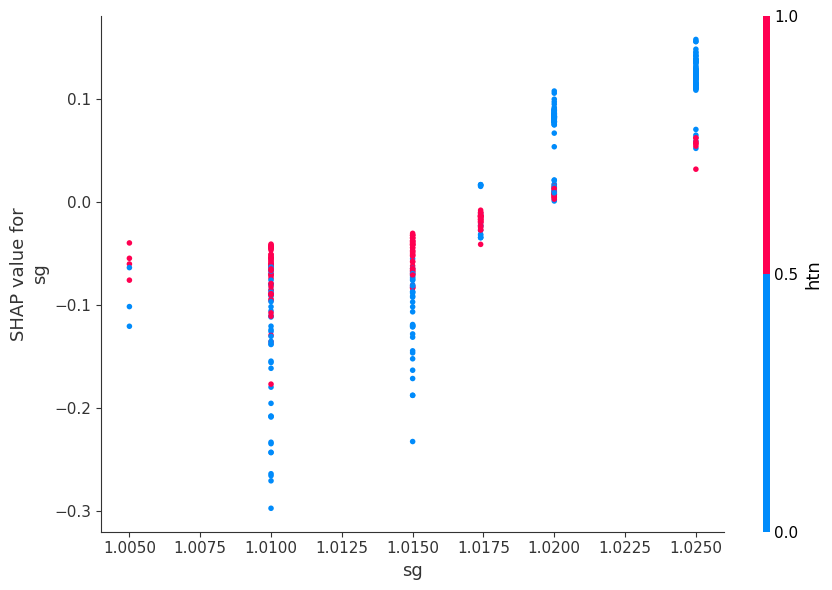

Figure saved to:
/content/drive/MyDrive/CKD Research Project/Figures/Notebook_05_XAI/Figure_04_SHAP_Dependence.png


In [ ]:
# =============================================================================
# SECTION 11 : SHAP DEPENDENCE PLOT
# =============================================================================

print("=" * 80)
print("Generating SHAP Dependence Plot...")
print("=" * 80)

# Most important feature
top_feature = feature_importance.iloc[0]["Feature"]

shap.dependence_plot(
    top_feature,
    shap_values[:, :, 1],
    X,
    interaction_index="auto",
    show=False
)

plt.gcf().set_size_inches(9, 6)

plt.tight_layout()

save_path = os.path.join(
    FIGURE_DIR,
    "Figure_04_SHAP_Dependence.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to:\n{save_path}")

In [ ]:
# =============================================================================
# SECTION 12 : LIME LOCAL EXPLANATION
# =============================================================================

print("=" * 80)
print("Generating LIME Local Explanation...")
print("=" * 80)

from lime.lime_tabular import LimeTabularExplainer

# Initialize Explainer
lime_explainer = LimeTabularExplainer(
    training_data=np.array(X),
    feature_names=X.columns.tolist(),
    class_names=["Not CKD", "CKD"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

print("LIME Explainer initialized successfully.")

Generating LIME Local Explanation...
LIME Explainer initialized successfully.


In [ ]:
# =============================================================================
# SECTION 13 : LIME EXPLANATION FOR ONE SAMPLE
# =============================================================================

sample_index = 0

lime_exp = lime_explainer.explain_instance(
    data_row=X.iloc[sample_index].values,
    predict_fn=extra_tree_model.predict_proba,
    num_features=10
)

print("=" * 80)
print("Prediction Probability")
print("=" * 80)

prediction = extra_tree_model.predict_proba(
    X.iloc[[sample_index]]
)

print(f"Not CKD : {prediction[0][0]:.4f}")
print(f"CKD     : {prediction[0][1]:.4f}")

print("\nTop Contributing Features")

for feature, weight in lime_exp.as_list():
    print(f"{feature:<40} {weight:.4f}")

Prediction Probability
Not CKD : 1.0000
CKD     : 0.0000

Top Contributing Features
0.00 < dm <= 1.00                        -0.1015
0.00 < htn <= 1.00                       -0.0958
hemo > 14.65                             0.0705
appet <= 0.00                            0.0629
pe <= 0.00                               0.0484
0.00 < al <= 2.00                        -0.0457
rbcc > 5.10                              0.0432
ane <= 0.00                              0.0383
su <= 0.00                               0.0297
1.02 < sg <= 1.02                        0.0252


In [ ]:
# =============================================================================
# SECTION 14 : SAVE LIME RESULTS
# =============================================================================

# HTML Report
html_path = os.path.join(
    RESULT_DIR,
    "LIME_Explanation.html"
)

lime_exp.save_to_file(html_path)

print(f"HTML report saved:\n{html_path}")


# CSV Report
lime_df = pd.DataFrame(
    lime_exp.as_list(),
    columns=["Feature", "Contribution"]
)

csv_path = os.path.join(
    RESULT_DIR,
    "LIME_Feature_Contribution.csv"
)

lime_df.to_csv(csv_path, index=False)

print(f"CSV report saved:\n{csv_path}")

display(lime_df)

HTML report saved:
/content/drive/MyDrive/CKD Research Project/Results/Notebook_05_XAI/LIME_Explanation.html
CSV report saved:
/content/drive/MyDrive/CKD Research Project/Results/Notebook_05_XAI/LIME_Feature_Contribution.csv


,Feature,Contribution
0,0.00 < dm <= 1.00,-0.101509
1,0.00 < htn <= 1.00,-0.095817
2,hemo > 14.65,0.070516
3,appet <= 0.00,0.062936
4,pe <= 0.00,0.048406
5,0.00 < al <= 2.00,-0.045741
6,rbcc > 5.10,0.043182
7,ane <= 0.00,0.038290
8,su <= 0.00,0.029715
9,1.02 < sg <= 1.02,0.025190


In [ ]:
# =============================================================================
# SECTION 15 : MODEL COMPARISON (WITHOUT SVC)
# =============================================================================

print("=" * 80)
print("Loading Machine Learning Model Comparison...")
print("=" * 80)

# Load results
comparison_path = os.path.join(
    PROJECT_DIR,
    "Results",
    "model_comparison.csv"
)

comparison_df = pd.read_csv(comparison_path)

# Remove SVC model
comparison_df = comparison_df[
    comparison_df["Model"] != "SVC"
].copy()

# Sort by Accuracy
comparison_df = comparison_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("\nFinal Model Ranking (Without SVC)")
display(comparison_df)

# Save cleaned comparison
save_path = os.path.join(
    RESULT_DIR,
    "Final_Model_Comparison.csv"
)

comparison_df.to_csv(
    save_path,
    index=False
)

print(f"\nComparison table saved to:\n{save_path}")

Loading Machine Learning Model Comparison...

Final Model Ranking (Without SVC)


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,LogisticRegression,0.9875,0.9677,1.0000,0.9836,0.9993
1,KNeighborsClassifier,0.9875,0.9677,1.0000,0.9836,0.9890
2,ExtraTreesClassifier,0.9875,1.0000,0.9667,0.9831,1.0000
3,RandomForestClassifier,0.9750,1.0000,0.9333,0.9655,0.9993
4,DecisionTreeClassifier,0.9750,1.0000,0.9333,0.9655,0.9667
5,GaussianNB,0.9750,0.9375,1.0000,0.9677,1.0000
6,LGBMClassifier,0.9750,1.0000,0.9333,0.9655,1.0000
7,CatBoostClassifier,0.9750,1.0000,0.9333,0.9655,0.9993
8,XGBClassifier,0.9625,1.0000,0.9000,0.9474,0.9993



Comparison table saved to:
/content/drive/MyDrive/CKD Research Project/Results/Notebook_05_XAI/Final_Model_Comparison.csv


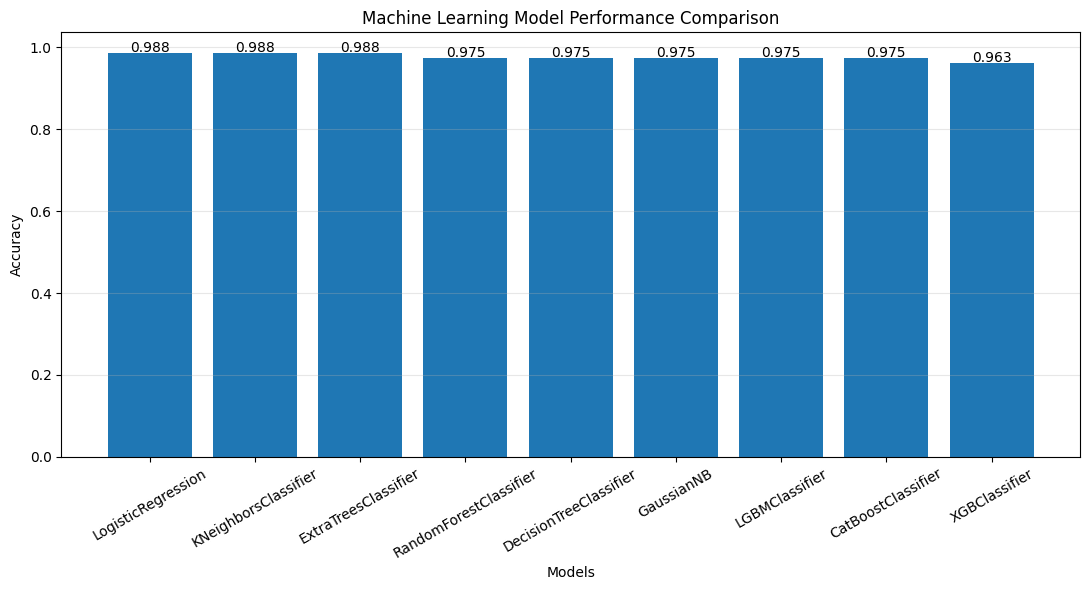

Figure saved to:
/content/drive/MyDrive/CKD Research Project/Figures/Notebook_05_XAI/Figure_05_Model_Comparison.png


In [ ]:
# =============================================================================
# SECTION 16 : MODEL COMPARISON VISUALIZATION
# =============================================================================

plt.figure(figsize=(11,6))

bars = plt.bar(
    comparison_df["Model"],
    comparison_df["Accuracy"]
)

# Highlight best model
best_idx = comparison_df["Accuracy"].idxmax()
bars[0].set_linewidth(2)

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.002,
        f"{height:.3f}",
        ha="center",
        fontsize=10
    )

plt.title("Machine Learning Model Performance Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

figure_path = os.path.join(
    FIGURE_DIR,
    "Figure_05_Model_Comparison.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved to:\n{figure_path}")

In [ ]:
# =============================================================================
# SECTION 17 : BEST MODEL SUMMARY
# =============================================================================

print("=" * 80)
print("BEST MODEL SUMMARY")
print("=" * 80)

# Find Extra Trees model automatically
extra_tree_rows = comparison_df[
    comparison_df["Model"].astype(str).str.contains(
        "extra",
        case=False,
        na=False
    )
]

# Use Extra Trees if found, otherwise use first row
if len(extra_tree_rows) > 0:
    best_model = extra_tree_rows.iloc[0]
    print("Best Model Selected: Extra Trees")
else:
    print("Extra Trees model not found!")
    print("Available Models:")
    print(comparison_df["Model"].tolist())

    print("\nUsing first ranked model instead.")
    best_model = comparison_df.iloc[0]

# Create Summary Table
summary = pd.DataFrame({
    "Metric": [
        "Best Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Value": [
        best_model["Model"],
        round(best_model["Accuracy"], 4),
        round(best_model["Precision"], 4),
        round(best_model["Recall"], 4),
        round(best_model["F1"], 4),
        round(best_model["ROC_AUC"], 4)
    ]
})

print("\nBest Model Summary")
display(summary)

# Save Summary
summary_path = os.path.join(
    RESULT_DIR,
    "Best_Model_Summary.csv"
)

summary.to_csv(
    summary_path,
    index=False
)

print(f"\nSummary saved to:\n{summary_path}")

BEST MODEL SUMMARY
Best Model Selected: Extra Trees

Best Model Summary


,Metric,Value
0,Best Model,ExtraTreesClassifier
1,Accuracy,0.9875
2,Precision,1.0
3,Recall,0.9667
4,F1-Score,0.9831
5,ROC-AUC,1.0



Summary saved to:
/content/drive/MyDrive/CKD Research Project/Results/Notebook_05_XAI/Best_Model_Summary.csv
